In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

PROCESSED_DIR = Path("../data/processed")
FRAMES_DIR = Path("../data/frames_v2")

df_train = pd.read_csv(PROCESSED_DIR / "train_frames_v2.csv")
df_val = pd.read_csv(PROCESSED_DIR / "val_frames_v2.csv")
df_test = pd.read_csv(PROCESSED_DIR / "test_frames_v2.csv")
df_sol = pd.read_csv(PROCESSED_DIR / "solution_v2.csv")

print("Data loaded successfully.")
print(f"Train frames: {len(df_train)}, Val frames: {len(df_val)}, Test frames: {len(df_test)}")

Data loaded successfully.
Train frames: 840, Val frames: 176, Test frames: 184


<Figure size 800x500 with 0 Axes>

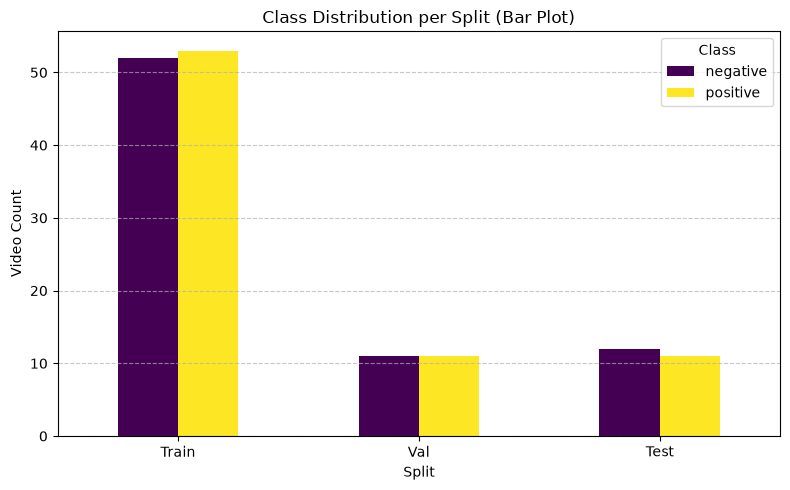

In [2]:
train_counts = df_train.drop_duplicates(subset=["video_id"])["label"].value_counts()
val_counts = df_val.drop_duplicates(subset=["video_id"])["label"].value_counts()
test_counts = df_test.drop_duplicates(subset=["video_id"])["label"].value_counts()

dist_df = pd.DataFrame({
    "Train": train_counts,
    "Val": val_counts,
    "Test": test_counts
}).fillna(0)

plt.figure(figsize=(8, 5))
dist_df.T.plot(kind="bar", stacked=False, figsize=(8, 5), colormap="viridis")
plt.title("Class Distribution per Split (Bar Plot)")
plt.xlabel("Split")
plt.ylabel("Video Count")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

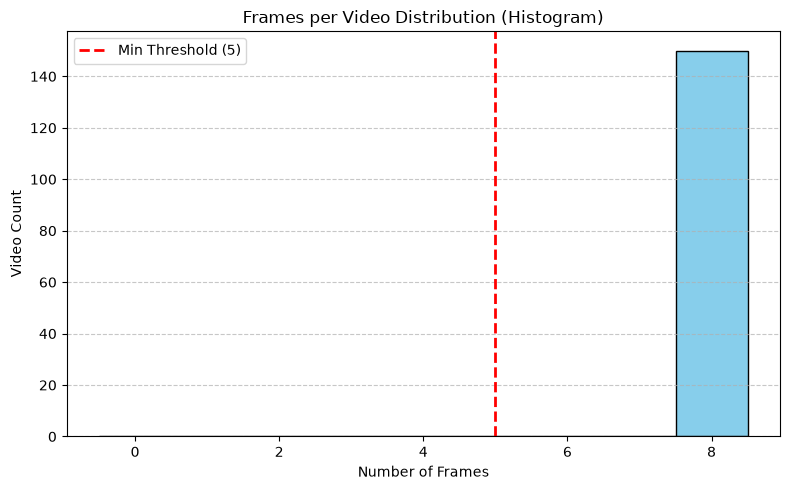

In [3]:
all_frames_df = pd.concat([df_train, df_val, df_test])
frame_counts = all_frames_df.groupby("video_id").size()

plt.figure(figsize=(8, 5))
plt.hist(frame_counts, bins=np.arange(0, frame_counts.max() + 2) - 0.5, edgecolor="black", color="skyblue")
plt.axvline(x=5, color="red", linestyle="--", linewidth=2, label="Min Threshold (5)")
plt.title("Frames per Video Distribution (Histogram)")
plt.xlabel("Number of Frames")
plt.ylabel("Video Count")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

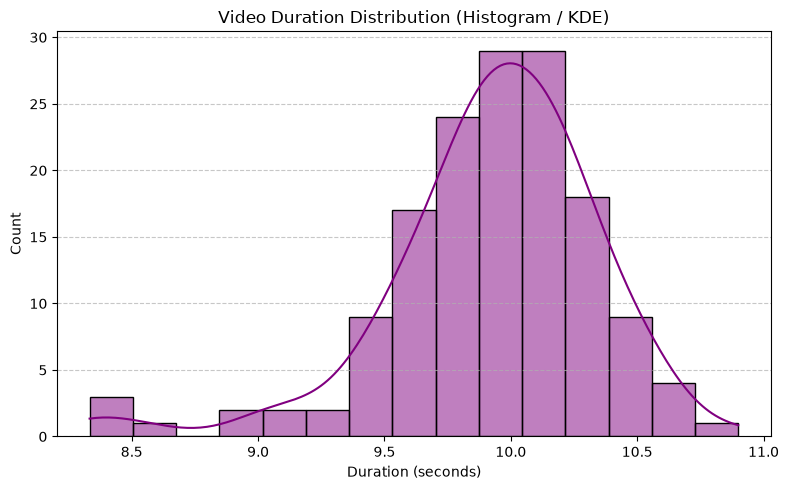

In [4]:
# Cell 4: Video Duration Distribution (Histogram / KDE)
video_meta = all_frames_df.drop_duplicates(subset=["video_id"])

# Load actual duration from processed valid_videos.csv if available, or compute correctly
df_valid_meta = pd.read_csv(PROCESSED_DIR / "valid_videos.csv")
merged_meta = video_meta.merge(df_valid_meta[["video_id", "duration"]], on="video_id", how="left")

plt.figure(figsize=(8, 5))
sns.histplot(merged_meta["duration"], kde=True, color="purple", bins=15)
plt.title("Video Duration Distribution (Histogram / KDE)")
plt.xlabel("Duration (seconds)")
plt.ylabel("Count")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

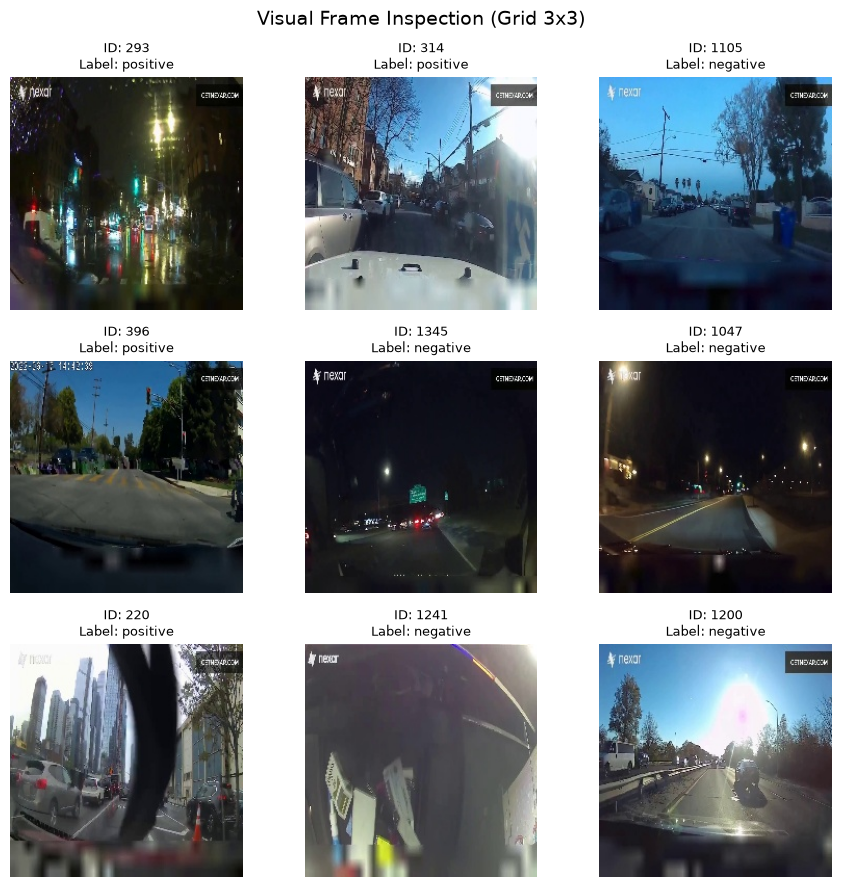

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
sample_rows = df_train.sample(9, random_state=42).reset_index(drop=True)

for idx, ax in enumerate(axes.flatten()):
    row = sample_rows.iloc[idx]
    img_path = row["frame_path"]
    img = cv2.imread(img_path)
    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax.imshow(img)
    ax.set_title(f"ID: {row['video_id']}\nLabel: {row['label']}", fontsize=9)
    ax.axis("off")

plt.suptitle("Visual Frame Inspection (Grid 3x3)", fontsize=14)
plt.tight_layout()
plt.show()

In [6]:

# Cell: Re-import Validation Module and Run All Integrity Checks
import sys
from pathlib import Path

_cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "src").is_dir()), _cwd)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.cv.validation import run_leakage_and_integrity_check

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

success = run_leakage_and_integrity_check(
    train_csv=PROCESSED_DIR / "train_frames_v2.csv",
    val_csv=PROCESSED_DIR / "val_frames_v2.csv",
    test_csv=PROCESSED_DIR / "test_frames_v2.csv",
    solution_csv=PROCESSED_DIR / "solution_v2.csv"
)

All integrity and sanity checks passed successfully.
